## [LAB-07] 추론통계

### 05-3_다중 공선성

In [2]:
from jussam import load_data
from helpers import *
from pandas import DataFrame, concat

# 연속형 자료형에서 값의 조합을 생성하는 함수
from itertools import combinations

# VIF 계산을 위한 statsmodels 패키지
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30

⚠️  'jussam' 패키지의 최신 버전이 출시되었습니다! (설치된 버전: 0.5.30, 최신 버전: 0.5.31)
   최신 버전으로 업데이트하려면 다음 명령어를 실행하세요:
   pip install --upgrade jussam



#### 2. 데이터 가져오기

In [3]:
df = load_data('vif_housing')
df

📚 어느 부동산 중개사무소에서 아파트 매물 250건의 정보를 수집하여 아파트 가격에 영향을 미치는 요인을 분석하기 위해 조사한 가상의 데이터


,면적_m2,면적_평,방_개수,지하철_거리_m,건물_연식_년
0,91.313,27.512,5.000,603.206,15.238
1,59.040,17.962,3.000,516.206,9.257
2,102.011,31.377,4.000,315.781,13.179
3,106.574,31.942,4.000,1173.652,20.700
4,37.175,11.172,1.000,1099.847,13.508
...,...,...,...,...,...
245,53.102,16.344,3.000,698.762,14.600
246,57.677,16.898,3.000,814.710,11.422
247,128.086,38.645,6.000,633.930,4.470
248,153.722,45.903,6.000,636.614,16.948


### #02 여러 변수의 상관 분석

#### 1. 각 변수들간의 조합 쌍 생성

- VIF를 계산하기 전에, 먼저 상관행렬로 변수들이 얼마나 닮았는지 눈으로 확인

In [4]:
# df의 컬럼명에 대한 조합 쌍을 생성한다.
column_pairs = list(combinations(df.columns, 2))
column_pairs

[('면적_m2', '면적_평'),
 ('면적_m2', '방_개수'),
 ('면적_m2', '지하철_거리_m'),
 ('면적_m2', '건물_연식_년'),
 ('면적_평', '방_개수'),
 ('면적_평', '지하철_거리_m'),
 ('면적_평', '건물_연식_년'),
 ('방_개수', '지하철_거리_m'),
 ('방_개수', '건물_연식_년'),
 ('지하철_거리_m', '건물_연식_년')]

#### 2. 변수 조합별 상관 분석

- 데이터프레임 객체의 corr() 메서드는 변수 조합별로 가정 확인 없이 일관된 상관계수를 도출하기 때문에<br>각각 상관분석을 수행하여 적절한 상관계수(Pearson, Spearman)를 도출해야 한다.

In [5]:
corr_df = DataFrame()
for col1, col2 in column_pairs:
    corr = my_stats.correlation(df, col1, col2, plot=False)
    corr_df = concat([corr_df, corr])

corr_df

method   coef  p-value strength  significant  \
x        y                                                          
면적_m2    면적_평      Spearman  0.999    0.000   Strong         True   
         방_개수      Spearman  0.897    0.000   Strong         True   
         지하철_거리_m  Spearman -0.087    0.171     Weak        False   
         건물_연식_년   Spearman  0.156    0.013     Weak         True   
면적_평     방_개수       Pearson  0.901    0.000   Strong         True   
         지하철_거리_m   Pearson -0.092    0.147     Weak        False   
         건물_연식_년    Pearson  0.160    0.011     Weak         True   
방_개수     지하철_거리_m   Pearson -0.098    0.121     Weak        False   
         건물_연식_년    Pearson  0.116    0.066     Weak        False   
지하철_거리_m 건물_연식_년    Pearson  0.081    0.204     Weak        False   

                   normality_x  normality_y  linearity  influential_outlier  \
x        y                                                                    
면적_m2    면적_평            False         True      False                False   
         방_개수            False         True       True                False   
         지하철_거리_m        False         True       True                False   
         건물_연식_년         False         True       True                False   
면적_평     방_개수             True         True       True                False   
         지하철_거리_m         True         True       True                False   
         건물_연식_년          True         True       True                False   
방_개수     지하철_거리_m         True         True       True                False   
         건물_연식_년          True         True       True                False   
지하철_거리_m 건물_연식_년          True         True       True                False   

                   high_skew  
x        y                    
면적_m2    면적_평          False  
         방_개수          False  
         지하철_거리_m      False  
         건물_연식_년       False  
면적_평     방_개수          False  
         지하철_거리_m      False  
         건물_연식_년       False  
방_개수     지하철_거리_m      False  
         건물_연식_년       False  
지하철_거리_m 건물_연식_년       False

> 다중 공선성이 의심되는 변수 관계
> - 면적_m2 ↔ 면적_평: 0.999
> - 면적_m2 ↔ 방_개수: 0.897
> - 면적_평 ↔ 방_개수: 0.901

#### 3. 상관행렬로 결과표 재배치

In [6]:
# corr_df 의 상관계수(coef)를 정방형 상관행렬(산점도 행렬)로 변환한다.
cols = list(df.columns)

# 대각선(자기 자신과의 상관)은 1.0 으로 초기화
corr_matrix = DataFrame(1.0, index=cols, columns=cols)

# 각 변수 조합의 상관계수를 대칭이 되도록 양쪽에 채운다.
for (col1, col2), coef in corr_df["coef"].items():
    corr_matrix.loc[col1, col2] = coef
    corr_matrix.loc[col2, col1] = coef

# 배경 색상(그라데이션)을 적용해서 출력
corr_matrix.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.3f}")

,면적_m2,면적_평,방_개수,지하철_거리_m,건물_연식_년
면적_m2,1.000,0.999,0.897,-0.087,0.156
면적_평,0.999,1.000,0.901,-0.092,0.160
방_개수,0.897,0.901,1.000,-0.098,0.116
지하철_거리_m,-0.087,-0.092,-0.098,1.000,0.081
건물_연식_년,0.156,0.160,0.116,0.081,1.000


#### 4. 산점도 행렬 시각화

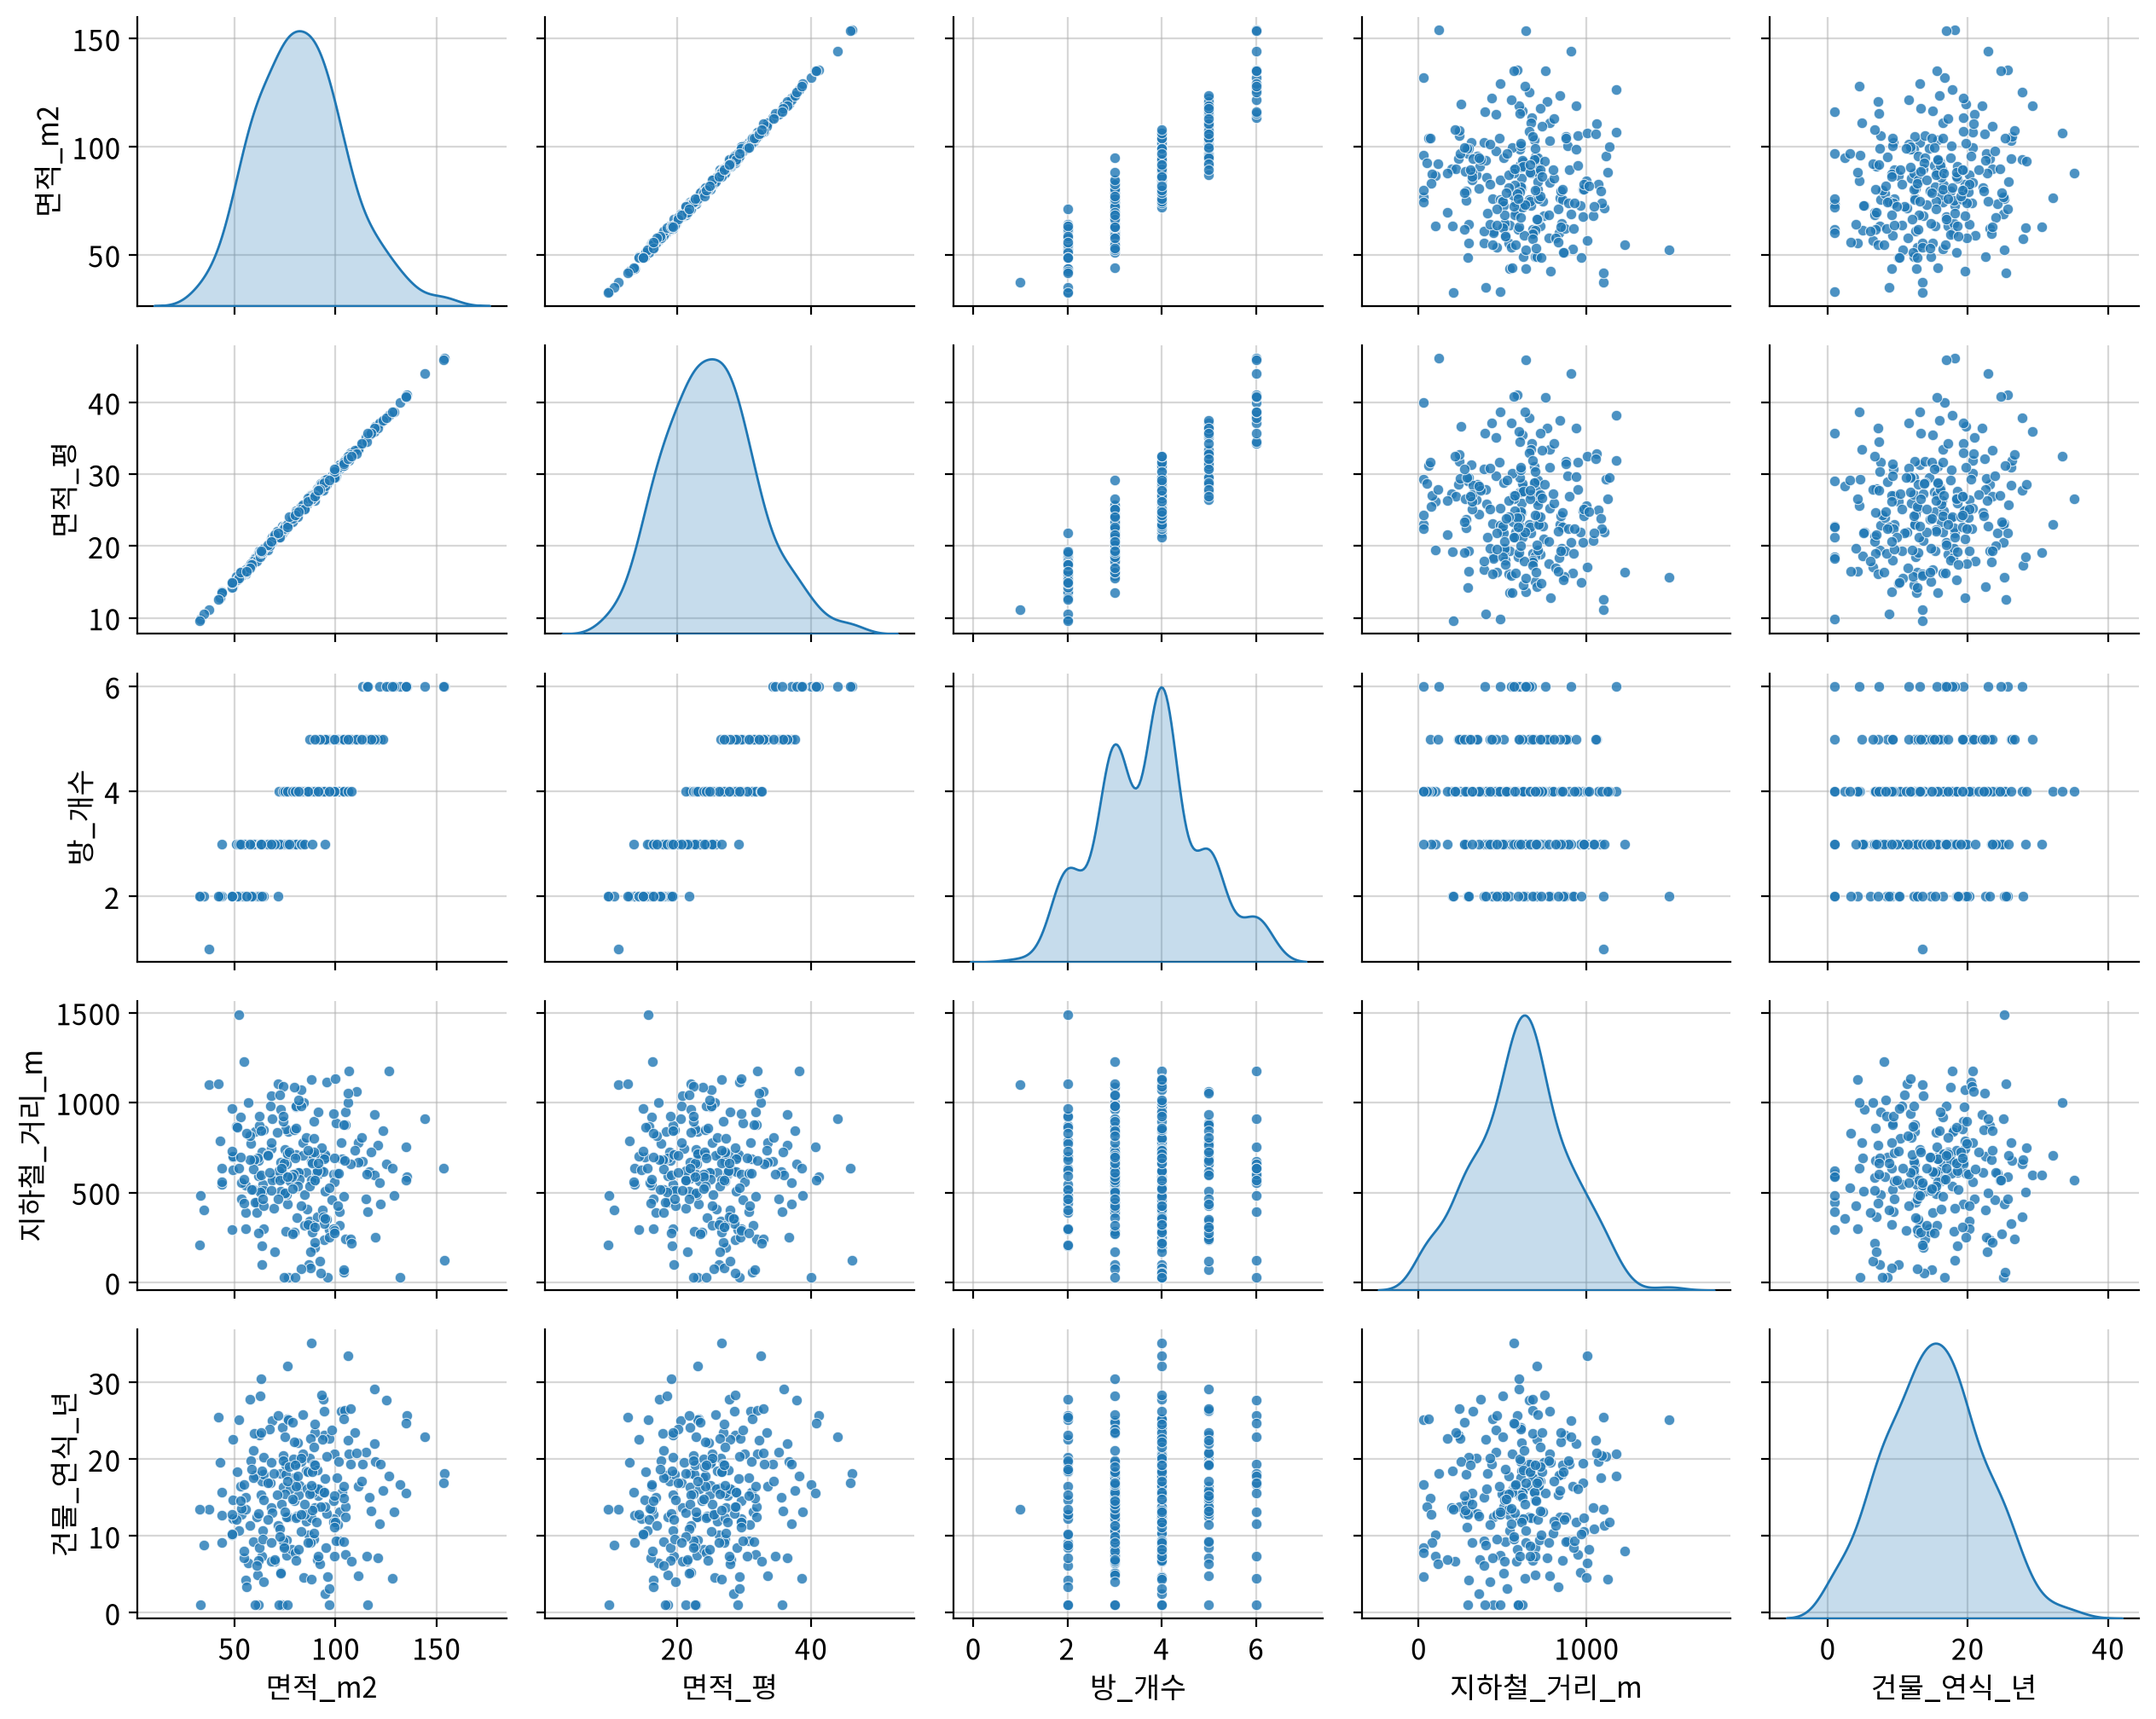

In [7]:
my_plot.pairplot(df, width=1280, height=1024)

#### 5. 모듈화 기능 확인

,면적_m2,면적_평,방_개수,지하철_거리_m,건물_연식_년
면적_m2,1.000,0.999,0.897,-0.087,0.156
면적_평,0.999,1.000,0.901,-0.092,0.160
방_개수,0.897,0.901,1.000,-0.098,0.116
지하철_거리_m,-0.087,-0.092,-0.098,1.000,0.081
건물_연식_년,0.156,0.160,0.116,0.081,1.000


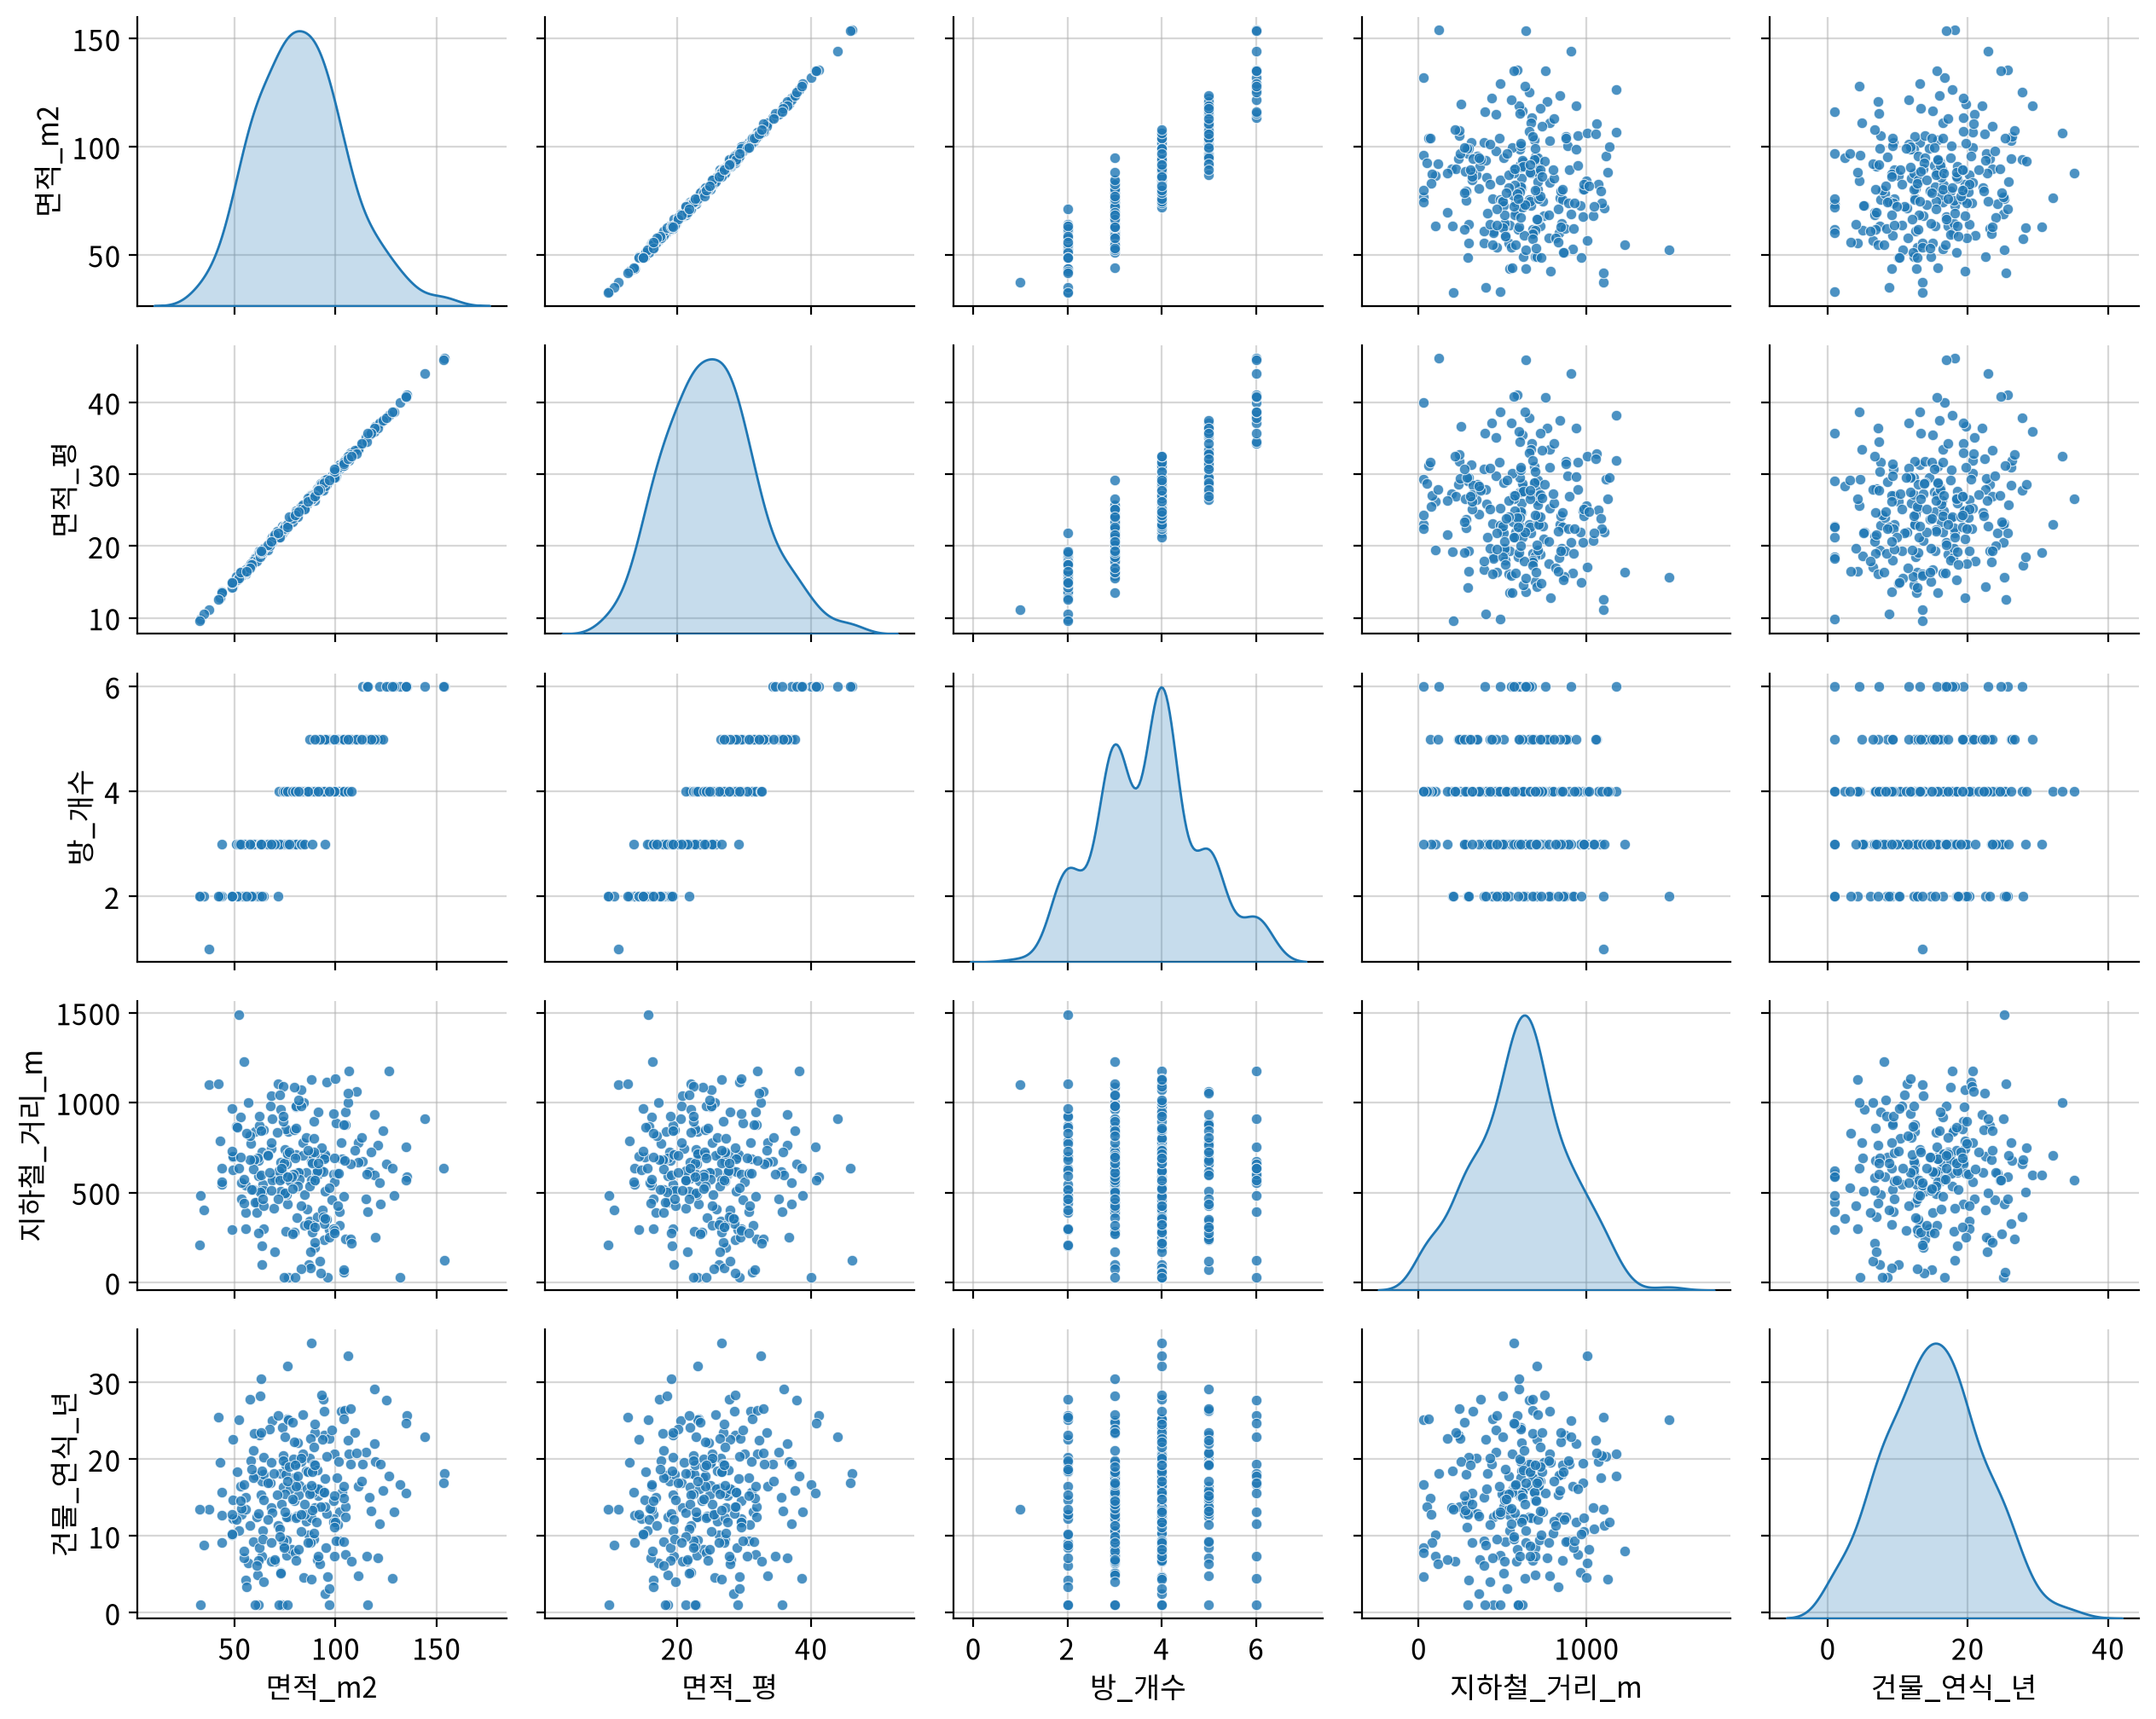

method   coef  p-value strength  significant  \
x        y                                                          
면적_m2    면적_평      Spearman  0.999    0.000   Strong         True   
         방_개수      Spearman  0.897    0.000   Strong         True   
         지하철_거리_m  Spearman -0.087    0.171     Weak        False   
         건물_연식_년   Spearman  0.156    0.013     Weak         True   
면적_평     방_개수       Pearson  0.901    0.000   Strong         True   
         지하철_거리_m   Pearson -0.092    0.147     Weak        False   
         건물_연식_년    Pearson  0.160    0.011     Weak         True   
방_개수     지하철_거리_m   Pearson -0.098    0.121     Weak        False   
         건물_연식_년    Pearson  0.116    0.066     Weak        False   
지하철_거리_m 건물_연식_년    Pearson  0.081    0.204     Weak        False   

                   normality_x  normality_y  linearity  influential_outlier  \
x        y                                                                    
면적_m2    면적_평            False         True      False                False   
         방_개수            False         True       True                False   
         지하철_거리_m        False         True       True                False   
         건물_연식_년         False         True       True                False   
면적_평     방_개수             True         True       True                False   
         지하철_거리_m         True         True       True                False   
         건물_연식_년          True         True       True                False   
방_개수     지하철_거리_m         True         True       True                False   
         건물_연식_년          True         True       True                False   
지하철_거리_m 건물_연식_년          True         True       True                False   

                   high_skew  
x        y                    
면적_m2    면적_평          False  
         방_개수          False  
         지하철_거리_m      False  
         건물_연식_년       False  
면적_평     방_개수          False  
         지하철_거리_m      False  
         건물_연식_년       False  
방_개수     지하철_거리_m      False  
         건물_연식_년       False  
지하철_거리_m 건물_연식_년       False

In [8]:
my_stats.multi_correlation(df, width=1280, height=1024)

### #03 다중 공선성 제거

#### 1. VIF 계산 함수 정의

In [9]:
def compute_vif(df, columns=None):
    """
    각 변수의 VIF를 statsmodels 패키지로 계산해서 반환.
    """

    # --- 1) 처리 대상 컬럼 결정 ---
    if columns is None:
        target = df.select_dtypes(include='number')
    else:
        # df에 존재하지 않는 컬럼이 전달되었는지 체크
        missing = []
        for col in columns:
            if col not in df.columns:
                missing.append(col)

        if missing:
            raise KeyError(f'df 에 존재하지 않는 컬럼입니다: {missing}')

        # 원본 데이터프레임에서 columns에 해당하는 컬럼만 추출
        target = df[columns]

        # VIF는 수치 행렬 연산이므로 비수치형이 섞이면 안 된다
        non_numeric = list(target.select_dtypes(exclude='number').columns)
        if non_numeric:
            raise TypeError(f'수치형이 아닌 컬럼은 VIF를 계산할 수 없습니다: {non_numeric}')

    # --- 2) VIF 계산 ---
    # 회귀모형에 절편(상수항)이 있어야 올바른 VIF가 나오므로 절편(상수항)을 추가
    X = add_constant(target)

    # 각 변수(열)별로 VIF를 하나씩 계산해서 리스트에 담는다.
    vif_values = []

    # 각 변수에 대해 VIF를 계산
    for i in range(X.shape[1]):
        # variance_inflation_factor는 i번째 변수에 대한 VIF를 계산
        vif_i = variance_inflation_factor(X.values, i)
        vif_values.append(vif_i)

    # 계산한 VIF 값들을 변수명과 함께 DataFrame으로 정리
    vif = DataFrame({'VIF': vif_values}, index=X.columns)

    # 상수항(const)은 분석 대상이 아니므로 제외하고 인덱스 오름차순으로 먼저 정렬
    # 그 후 VIF 기준 내림차순으로 정렬해서 반환
    # 단, 동점일 경우 기존 순서를 유지하도록 kind="stable" 옵션 사용
    vif = (vif.drop('const').sort_index()
           .sort_values(by='VIF', ascending=False, kind="stable"))

    return vif

#### 2. 구현한 함수 확인

In [10]:
vif = compute_vif(df)
vif

,VIF
면적_m2,546.195
면적_평,545.222
방_개수,5.352
건물_연식_년,1.040
지하철_거리_m,1.019


#### 3. VIF가 가장 큰 변수 제거

- 변수 하나만 제거하더라도 모든 VIF값이 변하기 때문에 일괄 삭제해서는 안된다.

In [11]:
# VIF 컬럼의 최댓값을 갖는 인덱스명 반환 --> "면적_m2"
worst = vif['VIF'].idxmax()
print(f"가장 VIF가 큰 변수: {worst} (VIF = {vif["VIF"].max():.1f}) -> 제거")

# 원본 데이터프레임에서 가장 VIF가 큰 컬럼을 제거한 새로운 데이터프레임 생성
df_reduced = df.drop(columns=[worst])

# VIF 재계산
compute_vif(df_reduced)

가장 VIF가 큰 변수: 면적_m2 (VIF = 546.2) -> 제거


,VIF
면적_평,5.400
방_개수,5.336
건물_연식_년,1.040
지하철_거리_m,1.019


#### 4. 무한루프로 다중공선성이 사라질 때까지 반복 제거

In [12]:
threshold = 10.0    # VIF 기준값
work = df.copy()    # 원본을 보존하기 위해 복사본으로 작업
step = 0            # 반복 단계 카운터

while True:         # 무한루프
    vif = compute_vif(work)     # VIF 계산
    max_vif = vif['VIF'].max()  # 가장 큰 VIF 값

    # 종료 조건: 가장 큰 VIF도 기준 미만이거나 남은 변수가 한개라면 종료
    if max_vif < threshold or len(work.columns) <= 1:
        print(f'\n완료! 남은 변수: {list(work.columns)}')
        print(f'최대 VIF = {max_vif:.2f}')
        break

    # 가장 VIF가 큰 변수를 찾아 제거하고 다시 반복
    worst = vif['VIF'].idxmax()
    step += 1
    print(f'[{step}단계] {worst} 제거 (VIF = {max_vif:.1f}) | 남은 변수: {list(work.columns)}')
    work = work.drop(columns=[worst])

# 최종적으로 다중공선성이 제거된 데이터프레임
df_final = work
df_final

[1단계] 면적_m2 제거 (VIF = 546.2) | 남은 변수: ['면적_m2', '면적_평', '방_개수', '지하철_거리_m', '건물_연식_년']

완료! 남은 변수: ['면적_평', '방_개수', '지하철_거리_m', '건물_연식_년']
최대 VIF = 5.40


,면적_평,방_개수,지하철_거리_m,건물_연식_년
0,27.512,5.000,603.206,15.238
1,17.962,3.000,516.206,9.257
2,31.377,4.000,315.781,13.179
3,31.942,4.000,1173.652,20.700
4,11.172,1.000,1099.847,13.508
...,...,...,...,...
245,16.344,3.000,698.762,14.600
246,16.898,3.000,814.710,11.422
247,38.645,6.000,633.930,4.470
248,45.903,6.000,636.614,16.948


### #04 모듈화 기능 테스트

#### 1. 다중 공선성 제거

In [13]:
df_final2 = my_prep.reduce_vif(df, threshold=10.0)
df_final2

[1단계] 면적_m2 제거 (VIF = 546.2)

완료! 남은 변수: ['건물_연식_년', '면적_평', '방_개수', '지하철_거리_m']
최대 VIF = 5.40


,면적_평,방_개수,지하철_거리_m,건물_연식_년
0,27.512,5.000,603.206,15.238
1,17.962,3.000,516.206,9.257
2,31.377,4.000,315.781,13.179
3,31.942,4.000,1173.652,20.700
4,11.172,1.000,1099.847,13.508
...,...,...,...,...
245,16.344,3.000,698.762,14.600
246,16.898,3.000,814.710,11.422
247,38.645,6.000,633.930,4.470
248,45.903,6.000,636.614,16.948


#### 2. 다중 공선성이 제거된 데이터의 VIF 확인

In [14]:
my_stats.compute_vif(df_final2)

,VIF
면적_평,5.400
방_개수,5.336
건물_연식_년,1.040
지하철_거리_m,1.019


#### 3. 다중 공선성이 제거된 데이터의 상관분석

In [15]:
my_stats.multi_correlation(df_final2, plot=False)

,면적_평,방_개수,지하철_거리_m,건물_연식_년
면적_평,1.000,0.901,-0.092,0.160
방_개수,0.901,1.000,-0.098,0.116
지하철_거리_m,-0.092,-0.098,1.000,0.081
건물_연식_년,0.160,0.116,0.081,1.000


method   coef  p-value strength  significant  normality_x  \
x        y                                                                      
면적_평     방_개수      Pearson  0.901    0.000   Strong         True         True   
         지하철_거리_m  Pearson -0.092    0.147     Weak        False         True   
         건물_연식_년   Pearson  0.160    0.011     Weak         True         True   
방_개수     지하철_거리_m  Pearson -0.098    0.121     Weak        False         True   
         건물_연식_년   Pearson  0.116    0.066     Weak        False         True   
지하철_거리_m 건물_연식_년   Pearson  0.081    0.204     Weak        False         True   

                   normality_y  linearity  influential_outlier  high_skew  
x        y                                                                 
면적_평     방_개수             True       True                False      False  
         지하철_거리_m         True       True                False      False  
         건물_연식_년          True       True                False      False  
방_개수     지하철_거리_m         True       True                False      False  
         건물_연식_년          True       True                False      False  
지하철_거리_m 건물_연식_년          True       True                False      False

> 변수 간의 상관 정도가 약해진 것을 확인할 수 있다.

---

## 연습문제

### 1. 카페 프랜차이즈 본사 데이터 분석팀

당신은 전국에 매장을 둔 카페 프랜차이즈 "BeanThere(빈데어)" 본사의 데이터 분석가입니다.

- 경영지원팀은 어떤 매장 특성이 일 매출에 영향을 주는가?를 회귀분석으로 밝히고 싶어 합니다.
- 그래서 200개 직영점에서 8개 변수를 수집해 왔습니다.

그런데 보고서를 받아 든 당신은 곧 이상한 점을 눈치챕니다.

> 면적을 평으로도 적고 m²로도 적어 놨네?
> 게다가 좌석수·직원수·방문객수·주문건수는 결국 '매장이 크고 사람이 많다'는 같은 이야기를 다른 말로 반복하는 것 같은데...?

bean_there 데이터 셋의 다중공선성을 진단하고 제거하여, 분석에 사용할 깔끔한 변수 집합을 만들어 봅니다.

| 변수명       | 설명                   |
| --------- | -------------------- |
| 면적_평      | 매장 면적 (평)            |
| 면적_m2     | 매장 면적 (m²)           |
| 좌석수       | 매장 내 좌석 수            |
| 직원수       | 근무 직원 수              |
| 일평균_방문객수  | 하루 평균 방문 고객 수        |
| 일평균_주문건수  | 하루 평균 주문 건수          |
| 지하철역_거리_m | 가장 가까운 지하철역까지 거리 (m) |
| 월광고비_만원   | 매장 월 광고비 (만원)        |

In [16]:
# 데이터 불러오기
df1 = load_data('bean_there')
df1

📚 BeanThere 프랜차이즈 200개 직영점의 매장 특성 데이터


,면적_평,면적_m2,좌석수,직원수,일평균_방문객수,일평균_주문건수,지하철역_거리_m,월광고비_만원
0,27.100,89.900,43.000,7.000,365.000,310.000,162.000,221.000
1,17.700,59.700,29.000,4.000,233.000,193.000,312.000,131.000
2,30.300,100.100,51.000,9.000,466.000,393.000,476.000,138.000
3,31.600,104.900,49.000,8.000,454.000,391.000,382.000,121.000
4,11.300,35.800,20.000,3.000,210.000,178.000,283.000,115.000
...,...,...,...,...,...,...,...,...
195,18.700,62.000,29.000,5.000,267.000,243.000,735.000,177.000
196,29.500,98.100,46.000,8.000,430.000,356.000,508.000,169.000
197,22.200,73.700,38.000,7.000,345.000,286.000,367.000,164.000
198,25.000,82.900,41.000,7.000,369.000,326.000,504.000,245.000


In [17]:
# 다중 공선성 제거
df1_final = my_prep.reduce_vif(df1, threshold=10.0)
df1_final

[1단계] 면적_평 제거 (VIF = 695.3)
[2단계] 일평균_방문객수 제거 (VIF = 126.7)
[3단계] 좌석수 제거 (VIF = 23.9)

완료! 남은 변수: ['면적_m2', '월광고비_만원', '일평균_주문건수', '지하철역_거리_m', '직원수']
최대 VIF = 8.25


,면적_m2,직원수,일평균_주문건수,지하철역_거리_m,월광고비_만원
0,89.900,7.000,310.000,162.000,221.000
1,59.700,4.000,193.000,312.000,131.000
2,100.100,9.000,393.000,476.000,138.000
3,104.900,8.000,391.000,382.000,121.000
4,35.800,3.000,178.000,283.000,115.000
...,...,...,...,...,...
195,62.000,5.000,243.000,735.000,177.000
196,98.100,8.000,356.000,508.000,169.000
197,73.700,7.000,286.000,367.000,164.000
198,82.900,7.000,326.000,504.000,245.000


In [18]:
# 다중 공선성이 제거된 데이터의 VIF 확인
my_stats.compute_vif(df1_final)

,VIF
면적_m2,8.247
일평균_주문건수,6.558
직원수,4.245
월광고비_만원,1.030
지하철역_거리_m,1.015


### 2. 자동차 연비와의 상관 분석

mtcars는 자동차 32종의 11개 속성에 대한 정보를 담고 있는 데이터 셋이다. 이 데이터에 대해 다음의 물음에 답하시오.

1. 연료 효율성 - 차량 무게와 연료 효율성 - 마력 두 쌍에 대해 상관분석을 수행하고, 각 쌍에 대해 어떤 상관계수(Pearson / Spearman)가 선택되었는지 답하시오.
2. 연료 효율성 - 배기량의 상관 강도는 어느 정도 인가?
3. 가장 강하게 연관되어 있는 속성은 무엇과 무엇인가?
4. 서로 상관이 없는 속성의 쌍을 모두 답하시오.
5. 각 변수에 대해 VIF를 계산하고, 기준값(10) 이상인 변수가 몇 개이며 무엇인지 답하시오.
6. 다중 공선성을 제거하기 위해서 어떤 순서대로 변수를 제거하면 되는지 답하시오.
7. 다중 공선성을 제거한 후에 최종적으로 남아 있는 변수는 어떤 것들인지 답하시오.

In [19]:
# 데이터 불러오기
df2 = load_data('mtcars')
df2.head()

📚 자동차 32종의 11개 속성에 대한 정보를 담고 있는 데이터 (출처: R 기본 데이터)

    field    description
--  -------  -------------------------------------------
 0  name     (str) 차종 이름 (인덱스)
 1  mpg      (str) 연료 효율성 (마일 당 갤런)
 2  cyl      (category) 실린더 수
 3  disp     (float) 배기량 (cubic inches)
 4  hp       (float) 마력 (horsepower)
 5  drat     (float) 후륜축 비율 (rear axle ratio)
 6  wt       (float) 차량 무게 (1000 파운드)
 7  qsec     (float) 1/4 마일 달성 시간 (초)
 8  vs       (category) 엔진 유형 (0: V 엔진, 1: S 엔진)
 9  am       (category) 변속기 형태 (0: 자동, 1: 수동)
10  gear     (category) 전진 기어 수 (전송 기어)
11  carb     (category) 기화기 개수 (carburetors)



,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
name,,,,,,,,,,,
Mazda RX4,21.000,6,160.000,110,3.900,2.620,16.460,0,1,4,4
Mazda RX4 Wag,21.000,6,160.000,110,3.900,2.875,17.020,0,1,4,4
Datsun 710,22.800,4,108.000,93,3.850,2.320,18.610,1,1,4,1
Hornet 4 Drive,21.400,6,258.000,110,3.080,3.215,19.440,1,0,3,1
Hornet Sportabout,18.700,8,360.000,175,3.150,3.440,17.020,0,0,3,2


In [25]:
# 데이터 타입 체크, 연속형 변수만 분석
df3 = my_qtcheck.set_type(df2, as_category=["cyl", "vs", "am", "gear", "carb"])
df3.info()

<class 'pandas.DataFrame'>
Index: 32 entries, Mazda RX4 to Volvo 142E
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   mpg     32 non-null     float32 
 1   cyl     32 non-null     category
 2   disp    32 non-null     float32 
 3   hp      32 non-null     int32   
 4   drat    32 non-null     float32 
 5   wt      32 non-null     float32 
 6   qsec    32 non-null     float32 
 7   vs      32 non-null     category
 8   am      32 non-null     category
 9   gear    32 non-null     category
 10  carb    32 non-null     category
dtypes: category(5), float32(5), int32(1)
memory usage: 2.7 KB
<class 'pandas.DataFrame'>
Index: 32 entries, Mazda RX4 to Volvo 142E
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   mpg     32 non-null     float32 
 1   cyl     32 non-null     category
 2   disp    32 non-null     float32 
 3   hp      32 non-null     int32   
 4   drat

,mpg,disp,hp,drat,wt,qsec
mpg,1.000,-0.909,-0.776,0.681,-0.886,0.419
disp,-0.909,1.000,0.791,-0.684,0.888,-0.434
hp,-0.776,0.791,1.000,-0.520,0.775,-0.708
drat,0.681,-0.684,-0.520,1.000,-0.712,0.091
wt,-0.886,0.888,0.775,-0.712,1.000,-0.225
qsec,0.419,-0.434,-0.708,0.091,-0.225,1.000


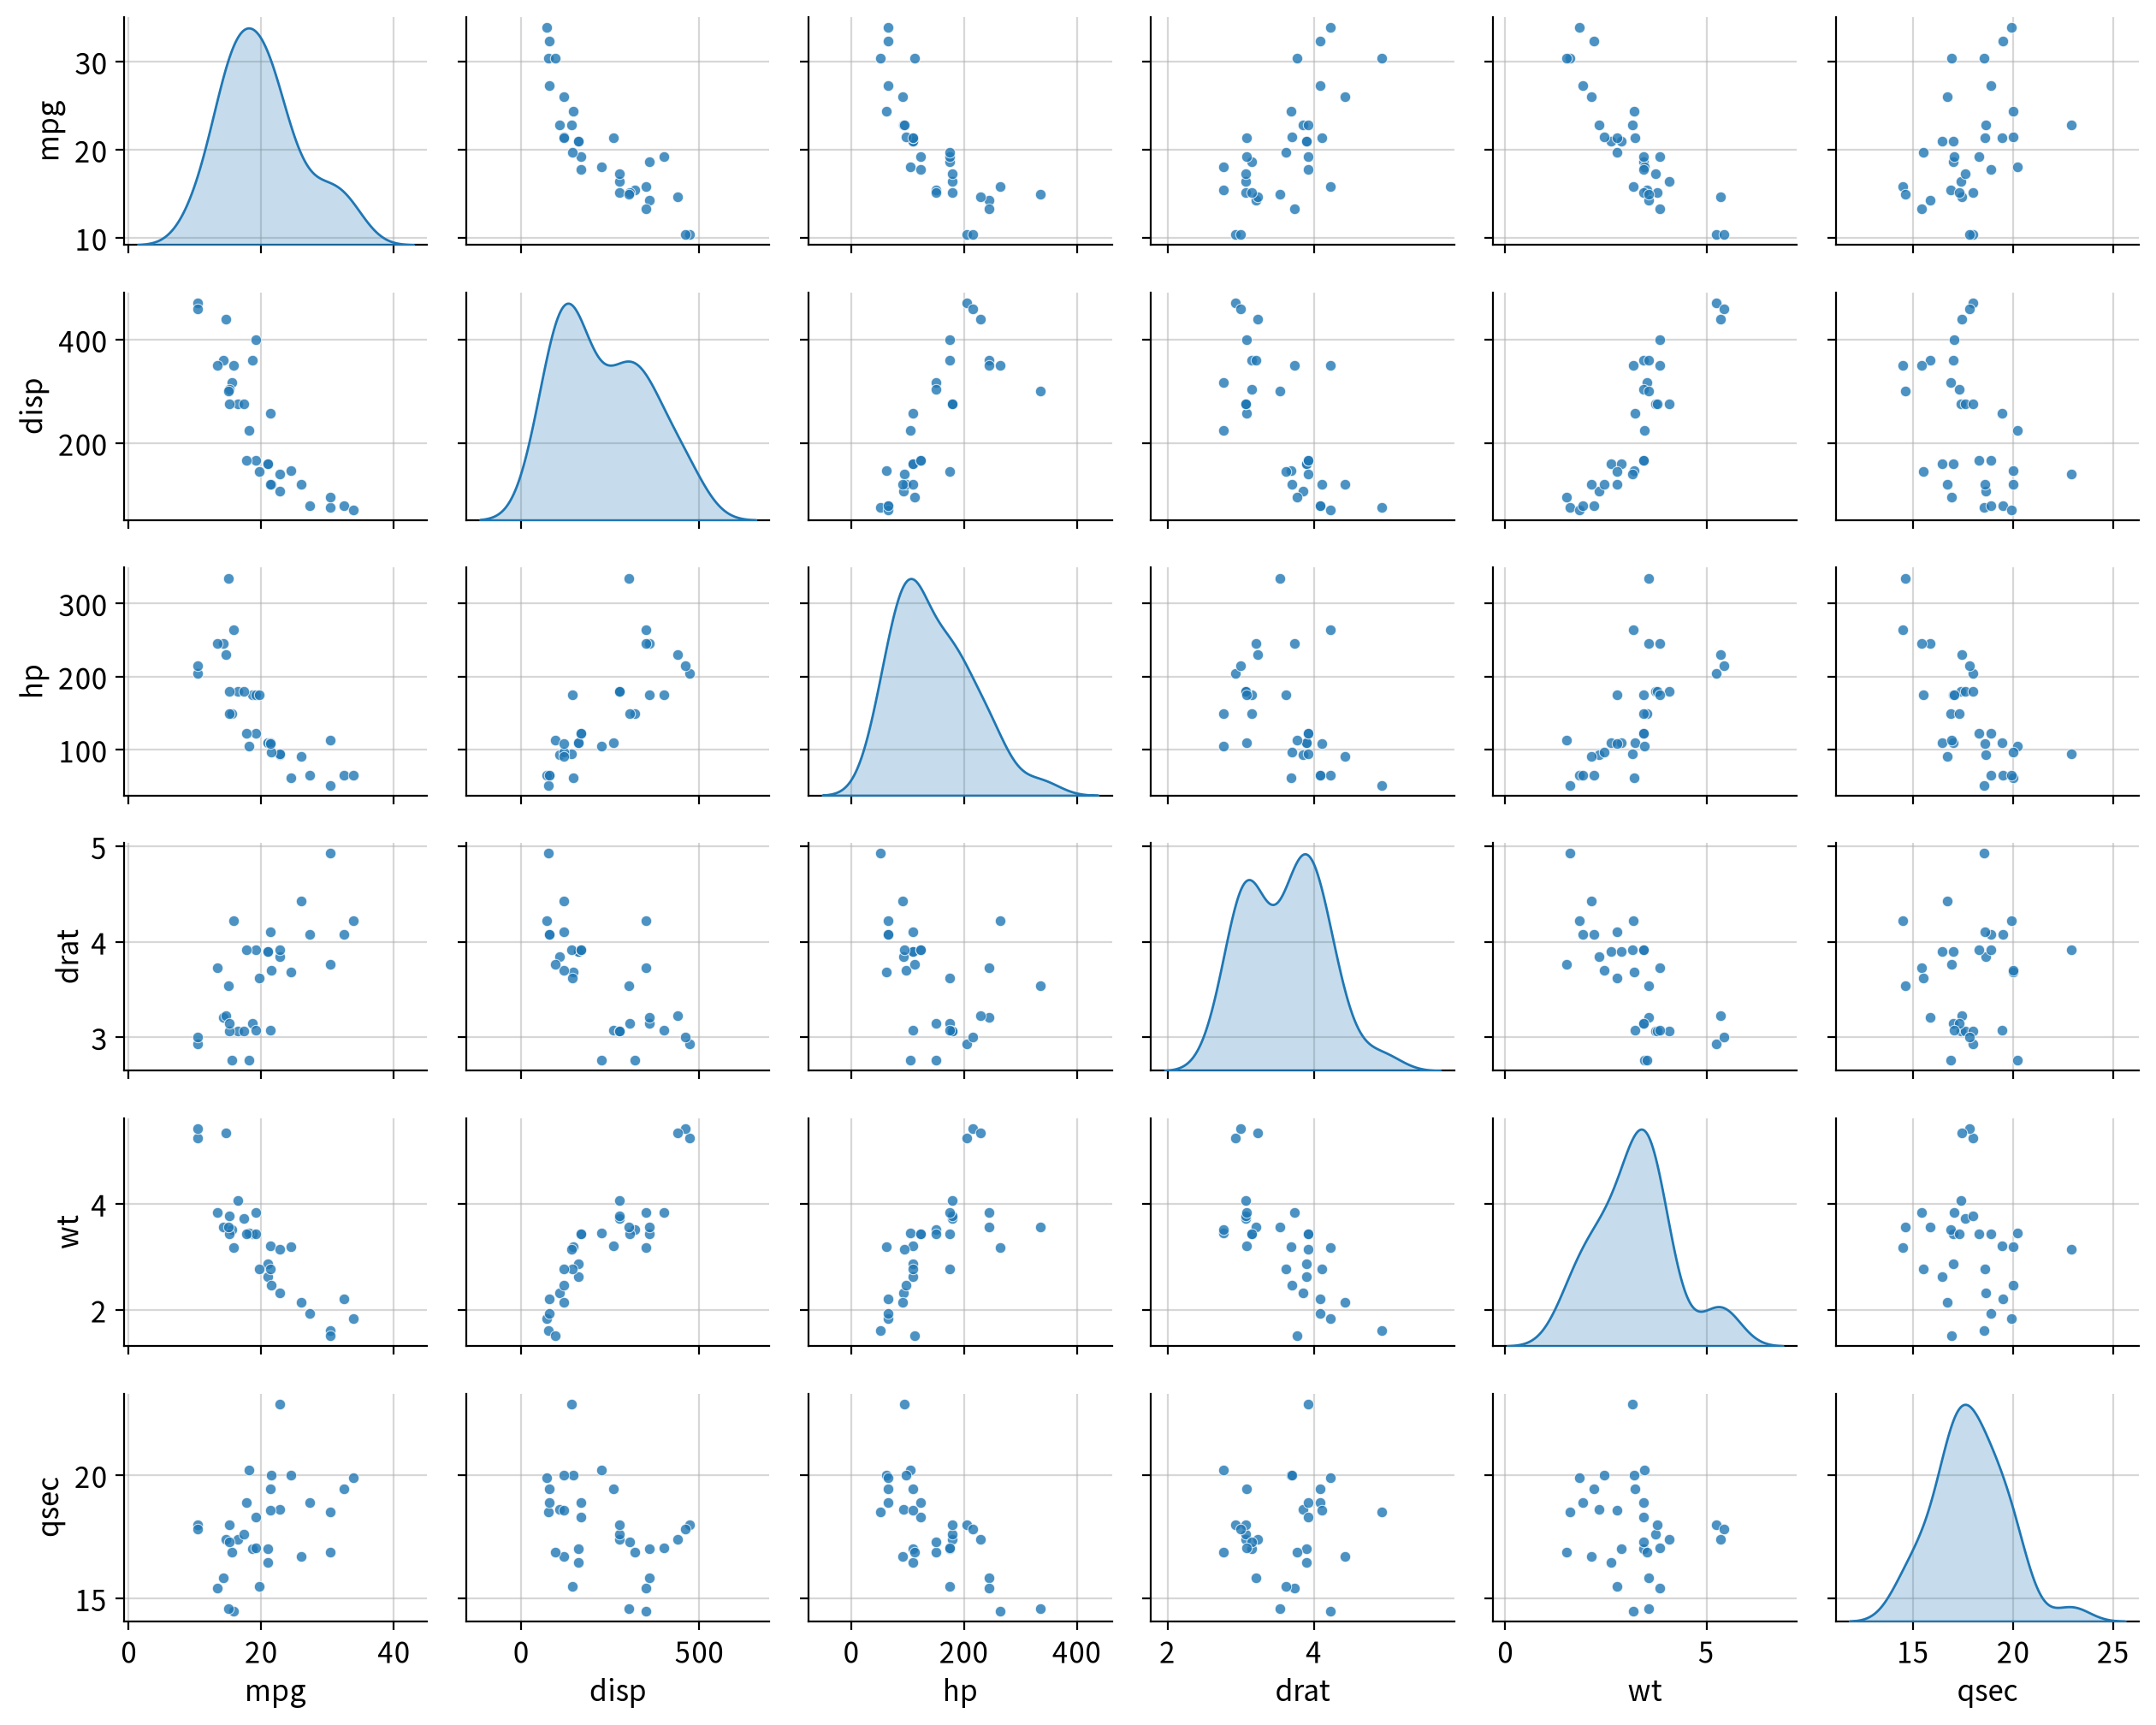

method   coef  p-value  strength  significant  normality_x  \
x    y                                                                    
mpg  disp  Spearman -0.909    0.000    Strong         True         True   
     hp     Pearson -0.776    0.000    Strong         True         True   
     drat   Pearson  0.681    0.000  Moderate         True         True   
     wt    Spearman -0.886    0.000    Strong         True         True   
     qsec   Pearson  0.419    0.017  Moderate         True         True   
disp hp     Pearson  0.791    0.000    Strong         True         True   
     drat  Spearman -0.684    0.000  Moderate         True         True   
     wt     Pearson  0.888    0.000    Strong         True         True   
     qsec   Pearson -0.434    0.013  Moderate         True         True   
hp   drat  Spearman -0.520    0.002  Moderate         True         True   
     wt    Spearman  0.775    0.000    Strong         True         True   
     qsec   Pearson -0.708    0.000    Strong         True         True   
drat wt     Pearson -0.712    0.000    Strong         True         True   
     qsec   Pearson  0.091    0.620      Weak        False         True   
wt   qsec  Spearman -0.225    0.215      Weak        False         True   

           normality_y  linearity  influential_outlier  high_skew  
x    y                                                             
mpg  disp         True      False                False      False  
     hp           True       True                False      False  
     drat         True       True                False      False  
     wt           True      False                False      False  
     qsec         True       True                False      False  
disp hp           True       True                False      False  
     drat         True      False                False      False  
     wt           True       True                False      False  
     qsec         True       True                False      False  
hp   drat         True      False                False      False  
     wt           True      False                False      False  
     qsec         True       True                False      False  
drat wt           True       True                False      False  
     qsec         True       True                False      False  
wt   qsec         True       True                 True      False

In [26]:
# 여러 변수의 상관 분석
my_stats.multi_correlation(df3, width=1280, height=1024)

In [27]:
# VIF 값 확인
vif = compute_vif(df3)
vif

,VIF
wt,10.368
disp,9.324
mpg,6.619
hp,5.565
qsec,3.430
drat,2.534


In [28]:
# 다중공선성 제거
df2_final = my_prep.reduce_vif(df3, threshold=10.0)
df2_final

[1단계] wt 제거 (VIF = 10.4)

완료! 남은 변수: ['disp', 'drat', 'hp', 'mpg', 'qsec']
최대 VIF = 5.53


,mpg,cyl,disp,hp,drat,qsec,vs,am,gear,carb
name,,,,,,,,,,
Mazda RX4,21.000,6,160.000,110,3.900,16.460,0,1,4,4
Mazda RX4 Wag,21.000,6,160.000,110,3.900,17.020,0,1,4,4
Datsun 710,22.800,4,108.000,93,3.850,18.610,1,1,4,1
Hornet 4 Drive,21.400,6,258.000,110,3.080,19.440,1,0,3,1
Hornet Sportabout,18.700,8,360.000,175,3.150,17.020,0,0,3,2
Valiant,18.100,6,225.000,105,2.760,20.220,1,0,3,1
Duster 360,14.300,8,360.000,245,3.210,15.840,0,0,3,4
Merc 240D,24.400,4,146.700,62,3.690,20.000,1,0,4,2
Merc 230,22.800,4,140.800,95,3.920,22.900,1,0,4,2


- 답변
1. 연료 효율성(mpg) - 차량 무게(wt)와 연료 효율성(mpg) - 마력(hp) 두 쌍에 대해 상관분석을 수행하고, 각 쌍에 대해 어떤 상관계수(Pearson / Spearman)가 선택되었는지 답하시오.
    - 연료 효율성(mpg) & 차량 무게(wt) : Spearman
    - 연료 효율성(mpg) & 마력(hp) : Pearson
2. 연료 효율성(mpg) - 배기량(disp)의 상관 강도는 어느 정도 인가?
    - Strong
3. 가장 강하게 연관되어 있는 속성은 무엇과 무엇인가?
    - 배기량(disp) & 연료 효율성(mpg)
4. 서로 상관이 없는 속성의 쌍을 모두 답하시오.
    - drat & qsec
    - wt & qsec
5. 각 변수에 대해 VIF를 계산하고, 기준값(10) 이상인 변수가 몇 개이며 무엇인지 답하시오.
    - 4개
        - disp	22.194
        - wt	17.942
        - cyl	15.382
        - hp	10.288
6. 다중 공선성을 제거하기 위해서 어떤 순서대로 변수를 제거하면 되는지 답하시오.
    - [1단계] wt 제거 (VIF = 10.4)
7. 다중 공선성을 제거한 후에 최종적으로 남아 있는 변수는 어떤 것들인지 답하시오.
    - **mpg, cyl, disp, hp, drat, qsec, vs, am, gear, carb** (제거된 변수: **wt**)